In [1]:
import cv2 as cv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import skimage as ski

import numpy.ma as ma
# import cupy as cp

import scipy as sp

import statistics as st

from itertools import cycle

# from sklearn.preprocessing import minmax_scale
import pandas as pd

from scipy import ndimage as ndi
from skimage.feature import peak_local_max

import mpl_toolkits as mpl

from pathlib import Path

import seaborn as sns

%matplotlib inline

In [2]:
matplotlib.rcParams['figure.dpi'] = 200
matplotlib.rcParams['figure.figsize'] = [6.4, 4.9]

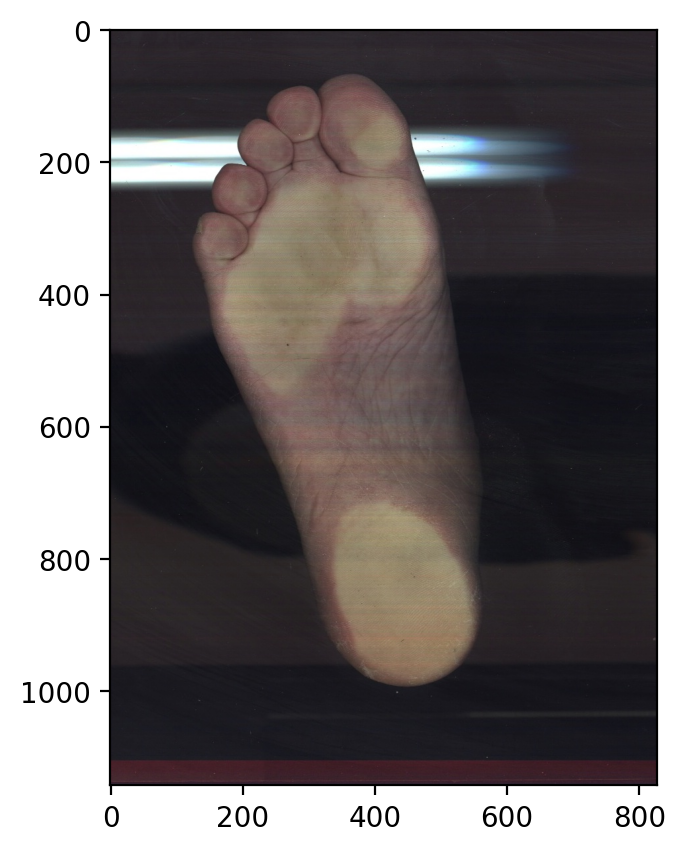

In [3]:
image = cv.imread('../обработка изображений/плантограммы/row1_Сканирование 11_12_photo1.jpg', cv.IMREAD_UNCHANGED)

image = cv.cvtColor(image, cv.COLOR_BGR2RGB)

plt.imshow(image)

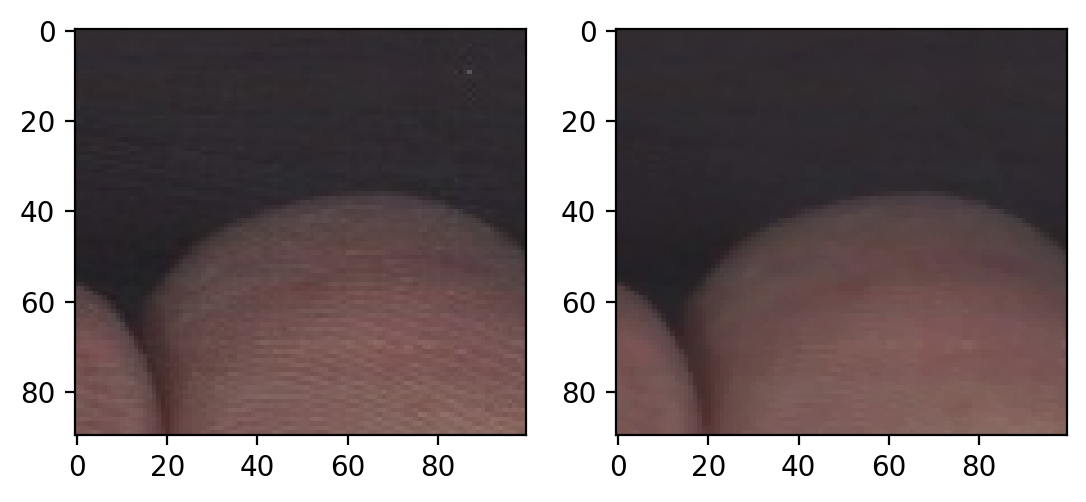

In [4]:
fig, axs = plt.subplots(1, 2)

roi = image[30:120, 300:400, :].copy()

axs[0].imshow(roi)

blur = cv.medianBlur(roi, 3)

axs[1].imshow(blur)


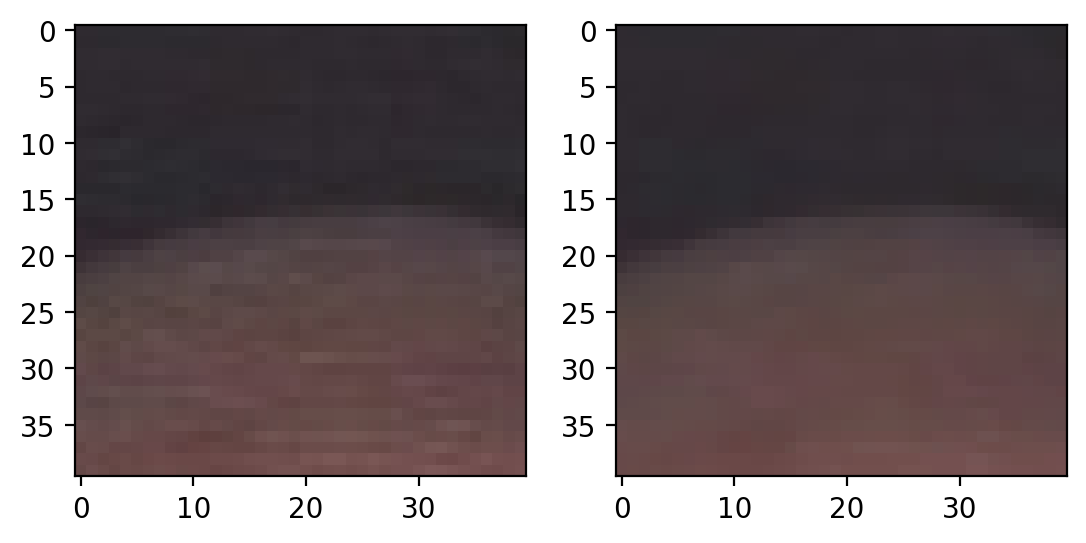

In [5]:
fig, axs = plt.subplots(1, 2)

roi = image[50:90, 340:380, :].copy()

axs[0].imshow(roi)

blur = cv.medianBlur(roi, 3)

axs[1].imshow(blur)


In [6]:
from tqdm import tqdm
datasetPath = Path('/home/dima/Documents/альбрехт/diasledVBAExtracted/')

preprocDatasetPath = Path('/home/dima/Documents/альбрехт/dataset-preprocessed')

for imageDirPath, subdirs, _ in datasetPath.walk():
    relativePath = imageDirPath.relative_to(datasetPath)
    
    destDir = preprocDatasetPath / relativePath
    
    if '_extracted' in destDir.as_posix():
        destDir = Path(destDir.as_posix().replace('_extracted', ''))

    print('mkdir:', destDir)

    destDir.mkdir(parents=True, exist_ok=True)


mkdir: /home/dima/Documents/альбрехт/dataset-preprocessed
mkdir: /home/dima/Documents/альбрехт/dataset-preprocessed/root
mkdir: /home/dima/Documents/альбрехт/dataset-preprocessed/root/Сапожников Артем
mkdir: /home/dima/Documents/альбрехт/dataset-preprocessed/root/Андреев Матвей Ринатович
mkdir: /home/dima/Documents/альбрехт/dataset-preprocessed/root/Котова Наталья Николаевна
mkdir: /home/dima/Documents/альбрехт/dataset-preprocessed/root/Корж Александра Борисовна
mkdir: /home/dima/Documents/альбрехт/dataset-preprocessed/root/Кашин Арсений Алексеевич
mkdir: /home/dima/Documents/альбрехт/dataset-preprocessed/root/Петров Петр
mkdir: /home/dima/Documents/альбрехт/dataset-preprocessed/root/Куликов Юрий Александрович
mkdir: /home/dima/Documents/альбрехт/dataset-preprocessed/root/Зеледеева Стелла Анатольевна
mkdir: /home/dima/Documents/альбрехт/dataset-preprocessed/root/Хачирова Халима Рустамовна
mkdir: /home/dima/Documents/альбрехт/dataset-preprocessed/root/Сиверская Ольга Викторовна
mkdir: /

In [25]:

i = 0

stop_i = 2

for sourceImagePath in tqdm(datasetPath.rglob('*.jpg')):
    relativePath = sourceImagePath.relative_to(datasetPath)

    destImagePath = preprocDatasetPath / relativePath

    if '_extracted' in destImagePath.as_posix():
        destImagePath = Path(destImagePath.as_posix().replace('_extracted', ''))

    destImagePath = destImagePath.with_suffix('.png')

    image = cv.imread(sourceImagePath)

    image = cv.medianBlur(image, 3)

    cv.imwrite(destImagePath, image)
    # print('cv.imwrite:', destImagePath)


4161it [04:01, 17.23it/s]
